# 05 · Iteración 3: modelo final, evaluación final y herramienta final

**Proyecto:** SCA-2026-01 · Herramienta de segmentación de clientes de Costanera Andina
**Etapa CRISP-DM y paquetes EDT:** Preparación (2.3.2 y 2.3.3), Modelado (2.4.3), Evaluación (2.5.3) y Despliegue (2.6.3)
**Iteración:** 3 de 3 (21/12/2026 al 08/01/2027)
**Equipo:** Felipe Ahumada Silva (Jefe de Proyecto) · Francisca Carrasco Lozano (Analista de Datos líder)

**Objetivo de este notebook:** construir la versión final de la herramienta solo con los clientes que renovaron su consentimiento (Ley 21.719), comprobar que los segmentos siguen siendo los mismos, cerrar la revisión de equidad pendiente (D-05) y dejar funcionando la comparación entre segmentaciones y el aviso de cambios en los datos.

**Requerimientos que se trabajan:** RF.5 (segmento para cada cliente con consentimiento), RF.11 (comparar con la segmentación anterior), RF.12 (aviso cuando los datos cambian), RNF.4 (100 % con consentimiento vigente) y RNF.12 (registro de uso).

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import adjusted_rand_score
from costanera import carga, config, evaluacion, fichas, modelado, monitoreo, pipeline, preparacion
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
FIG = config.FIGURAS
FIG.mkdir(parents=True, exist_ok=True)

## 1. Corte con consentimiento vigente (2.3.2)

La campaña de renovación de Fidelización cerró el 22/12. Su resultado llega en un archivo aparte, con una fila por cliente. Quien no aparece en el archivo o respondió que no, queda fuera del ambiente analítico.

*Nota del caso académico:* el archivo original no trae consentimiento, así que la respuesta a la campaña está simulada con semilla fija (`data/raw/consentimiento_renovacion_2026-12.csv`).

In [2]:
validos, resumen = carga.cargar()
con_consentimiento, rc = carga.agregar_consentimiento(validos)
pd.Series(rc, name="campaña de renovación").to_frame()

,campaña de renovación
clientes,200
con_consentimiento,172
sin_respuesta,0
pct_con_consentimiento,86.0
sobre_minimo,True


Renovaron 172 de 200 clientes (86 %), sobre el mínimo de 150 que fijó el plan de contingencia del riesgo R14, así que la versión final se construye con la base consentida.

Antes de modelar hay que revisar si los que renovaron se parecen al total. Si la campaña hubiera dejado fuera a un grupo (por ejemplo, a los mayores), los segmentos cambiarían por eso y no por los clientes.

In [3]:
total = preparacion.preparar(validos)
consentida = preparacion.preparar(con_consentimiento, solo_con_consentimiento=True)
comparacion = pd.DataFrame({
    "total (%)": total["tramo_etario"].value_counts(normalize=True).mul(100),
    "con consentimiento (%)": consentida["tramo_etario"].value_counts(normalize=True).mul(100),
}).loc[config.ETIQUETAS_TRAMOS]
comparacion.loc["mujeres"] = [total["genero"].eq("F").mean() * 100, consentida["genero"].eq("F").mean() * 100]
comparacion.round(1)

,total (%),con consentimiento (%)
tramo_etario,,
18-29,27.5,28.5
30-44,38.0,39.0
45-59,24.5,23.3
60+,10.0,9.3
mujeres,56.0,57.0


In [4]:
monitoreo.alerta_deriva(total, consentida)

,variable,psi,alerta
0,ingreso_anual_k,0.006,False
1,indice_gasto,0.009,False


La composición por edad y género casi no cambia (diferencias de un punto o menos) y el PSI de las dos variables del modelo está muy por debajo de 0,10. La base consentida es representativa del total.

## 2. Actualización de la preparación (2.3.3)

Se aplica el mismo pipeline de las iteraciones anteriores: seudónimo SHA-256, tramo etario y escalamiento. La base queda versionada como `base_analitica_v3`.

In [5]:
X, _ = preparacion.escalar(consentida)
print("Clientes en la base v3:", len(consentida))
print("Columnas:", list(consentida.columns))
print("¿Queda el identificador original?", "id_cliente" in consentida)

Clientes en la base v3: 172
Columnas: ['seudonimo', 'genero', 'edad', 'educacion', 'estado_civil', 'ingreso_anual_k', 'indice_gasto', 'consentimiento', 'tramo_etario']
¿Queda el identificador original? False


## 3. Modelo final (2.4.3)

Con menos clientes, el número de segmentos podría cambiar. Se vuelve a revisar k de 3 a 8 con la silueta y el tamaño mínimo, y se registra cada corrida.

In [6]:
filas = []
for k in range(3, 9):
    et = modelado.kmeans(X, k).labels_
    r = evaluacion.evaluar(X, et, consentida, k, con_estabilidad=(k == 5))
    filas.append({"k": k, "silueta": r["silueta"], "segmento mínimo (%)": r["tamano_min_pct"]})
    evaluacion.registrar_experimento("It.3", "K-means", f"k={k}", config.VARIABLES_MODELO, r,
                                     "elegido" if k == 5 else "descartado")
eleccion = pd.DataFrame(filas).set_index("k")
eleccion.round(3)

,silueta,segmento mínimo (%)
k,,
3,0.459,17.442
4,0.482,11.047
5,0.538,11.047
6,0.527,5.233
7,0.516,4.651
8,0.456,4.651


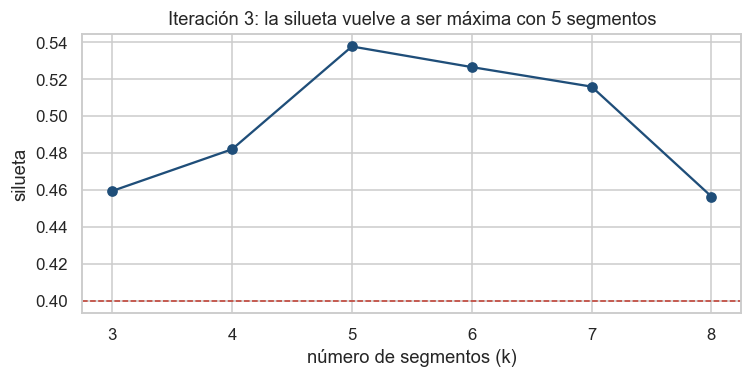

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(eleccion.index, eleccion["silueta"], "-o", color="#1f4e79")
ax.axhline(config.CRITERIOS["silueta_min"], color="#c0392b", ls="--", lw=1)
ax.set_xlabel("número de segmentos (k)"); ax.set_ylabel("silueta")
ax.set_title("Iteración 3: la silueta vuelve a ser máxima con 5 segmentos")
plt.tight_layout(); plt.savefig(FIG / "05_eleccion_k_final.png", bbox_inches="tight"); plt.show()

Con la base consentida, 5 segmentos sigue siendo la mejor opción. Ahora se compara con la iteración 2, cliente por cliente (RF.11). Para eso se vuelve a correr la herramienta v2 sobre toda la base y se cruzan los seudónimos.

In [8]:
v2 = pipeline.ejecutar(k=5, version="v2", consentimiento=None, registrar=False)
final = pipeline.ejecutar(k=5, version="v3", anterior=v2["ruta_base"], registrar=False)
cmp_ = final["comparacion"]
print(f"Clientes comparados: {cmp_['clientes_comparados']}  ·  cambiaron de segmento: {cmp_['cambiaron']} ({cmp_['pct_cambiaron']} %)")
cmp_["matriz"]

Clientes comparados: 172  ·  cambiaron de segmento: 1 (0.6 %)


nuevo,Entusiastas,Estándar,Potencial por activar,Premium,Sensibles al precio
anterior,,,,,
Entusiastas,19,0,0,0,0
Estándar,0,69,1,0,0
Potencial por activar,0,0,27,0,0
Premium,0,0,0,36,0
Sensibles al precio,0,0,0,0,20


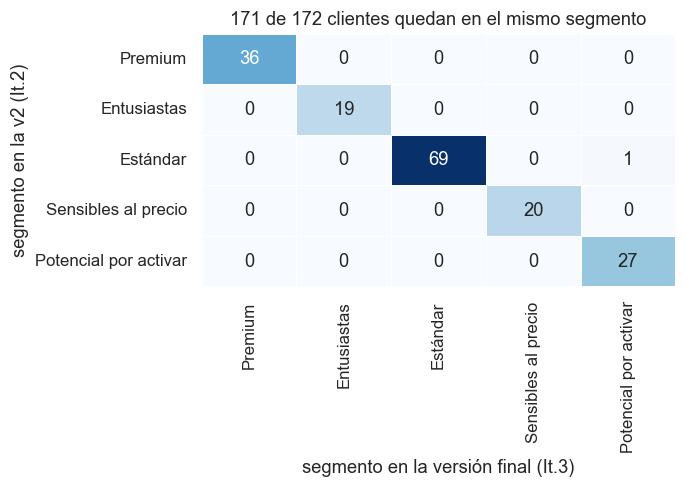

In [9]:
orden = ["Premium", "Entusiastas", "Estándar", "Sensibles al precio", "Potencial por activar"]
m = cmp_["matriz"].reindex(index=orden, columns=orden, fill_value=0)
fig, ax = plt.subplots(figsize=(6.4, 4.6))
sns.heatmap(m, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, linewidths=.5)
ax.set_xlabel("segmento en la versión final (It.3)"); ax.set_ylabel("segmento en la v2 (It.2)")
ax.set_title("171 de 172 clientes quedan en el mismo segmento")
plt.tight_layout(); plt.savefig(FIG / "05_comparacion_it2_it3.png", bbox_inches="tight"); plt.show()

Los segmentos son los mismos: solo un cliente cambia de segmento, y en el límite entre dos grupos vecinos. Las fichas que Marketing validó en la iteración 2 siguen sirviendo.

## 4. Evaluación final (2.5.3)

In [10]:
r3 = final["resultado"]
pd.Series(r3).round(3).to_frame("iteración 3").T

,silueta,tamano_min_pct,estabilidad,ruido_pct,brecha_genero_pp,brecha_tramo_etario_pp
iteración 3,0.538,11.047,0.958,0.0,4.345,45.196


In [11]:
pd.Series(final["chequeos"], name="cumple").to_frame()

,cumple
"silueta >= 0,40",True
ningún segmento < 5 %,True
"estabilidad >= 0,80",True
brecha genero <= 15 pp,True
brecha tramo_etario <= 15 pp,False


In [12]:
tabla = final["fichas"]
tabla[["segmento", "nombre", "clientes", "pct_clientes", "edad_media", "ingreso_medio_k", "indice_gasto_medio",
       "pct_mujeres", "pct_18-29", "pct_30-44", "pct_45-59", "pct_60+"]]

,segmento,nombre,clientes,pct_clientes,edad_media,ingreso_medio_k,indice_gasto_medio,pct_mujeres,pct_18-29,pct_30-44,pct_45-59,pct_60+
0,1,Premium,36,20.9,32.8,86.6,82.0,52.8,19.4,80.6,0.0,0.0
1,2,Entusiastas,19,11.0,25.2,25.5,78.6,52.6,73.7,26.3,0.0,0.0
2,3,Estándar,69,40.1,42.2,54.9,49.7,60.9,30.4,18.8,31.9,18.8
3,4,Sensibles al precio,20,11.6,45.1,26.6,21.8,60.0,10.0,30.0,45.0,15.0
4,5,Potencial por activar,28,16.3,39.5,87.4,18.0,53.6,17.9,50.0,32.1,0.0


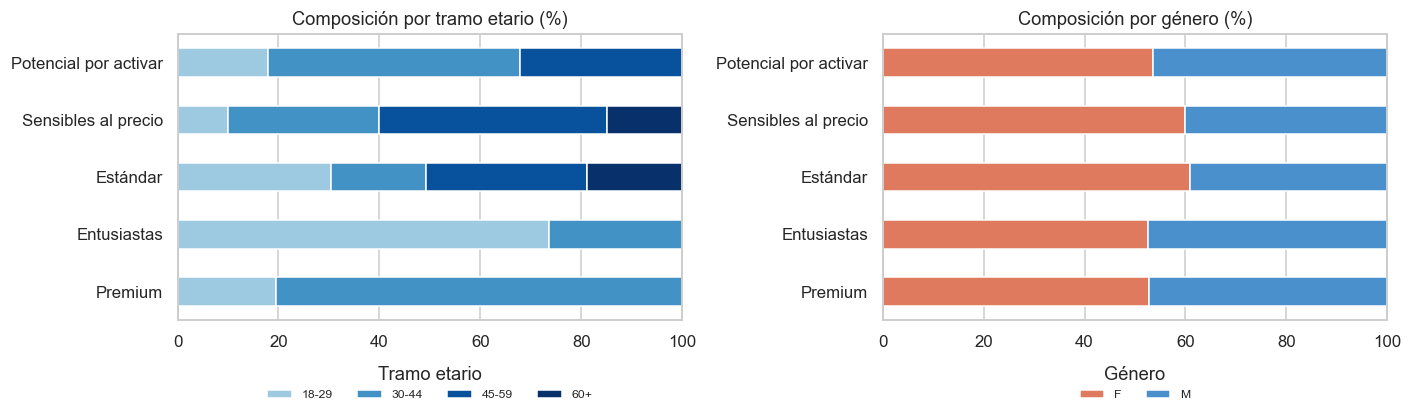

In [13]:
base3 = final["base"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
comp_t = evaluacion.composicion(base3, "segmento", "tramo_etario")[config.ETIQUETAS_TRAMOS]
comp_t.index = tabla.set_index("segmento").loc[comp_t.index, "nombre"]
comp_t.plot.barh(stacked=True, ax=ax[0], color=["#9ecae1", "#4292c6", "#08519c", "#08306b"], edgecolor="white")
ax[0].set_title("Composición por tramo etario (%)")
comp_g = evaluacion.composicion(base3, "segmento", "genero"); comp_g.index = comp_t.index
comp_g.plot.barh(stacked=True, ax=ax[1], color=["#e07a5f", "#4a90cd"], edgecolor="white"); ax[1].set_title("Composición por género (%)")
for a, titulo in zip(ax, ["Tramo etario", "Género"]):
    a.legend(title=titulo, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, fontsize=8, frameon=False)
    a.set_ylabel(""); a.set_xlim(0, 100)
plt.tight_layout(); plt.savefig(FIG / "05_composicion_final.png", bbox_inches="tight"); plt.show()

**Resultado del control técnico:** cumple silueta (0,54), tamaño mínimo (11 %), estabilidad (0,96) y equidad por género (4,3 pp, mejor que en la iteración 2). **La equidad por edad sigue sin cumplir: 45,2 pp.** Premium y Entusiastas siguen sin clientes de 45 años o más.

### Cierre de la desviación D-05

La iteración 3 confirma lo que se vio en la iteración 2: la brecha no viene del algoritmo ni de la muestra, sino de que el índice de gasto baja con la edad. Ningún ajuste del modelo la corrige sin usar la edad como variable, y eso se descartó por el riesgo R7. Lo que sí se puede controlar es el **uso** de los segmentos. La tabla siguiente muestra dónde están los clientes de 45 años o más: si Marketing diseña campañas solo para Premium y Entusiastas, ellos quedan fuera.

In [14]:
mayores = base3[base3["tramo_etario"].isin(["45-59", "60+"])]
donde = mayores["nombre_segmento"].value_counts().rename("clientes de 45+").to_frame()
donde["% de los 45+"] = (donde["clientes de 45+"] / len(mayores) * 100).round(1)
donde

,clientes de 45+,% de los 45+
nombre_segmento,,
Estándar,35,62.5
Sensibles al precio,12,21.4
Potencial por activar,9,16.1


Los clientes de 45 años o más están en Estándar, Sensibles al precio y Potencial por activar. Las acciones que cierran D-05, aprobadas por el patrocinador en la evaluación final (H4, 08/01):

1. Se mantienen la alerta de equidad en las fichas y la regla de la lista de revisión de campañas (RF.9): ninguna campaña por segmento puede quitar beneficios base a otros clientes.
2. El informe de recomendaciones incluye una campaña para los clientes de 45+ de Potencial por activar (alto ingreso, bajo gasto), que es el grupo con más oportunidad.
3. La brecha por edad se mide en cada recálculo y queda como indicador del procedimiento de monitoreo (2.6.4).

**D-03 (ventas reales):** Administración confirmó que no puede entregar ventas por tienda antes del cierre. El índice de gasto queda validado solo internamente (notebook 01) y se informa como limitación; contrastarlo con ventas queda como recomendación para una segunda etapa (RF.13).

**Decisión firmada (08/01, H4):** la herramienta final se aprueba, con la brecha por edad como riesgo aceptado y controlado por el uso.

## 5. Herramienta final (2.6.3)

La versión final se ejecuta con un comando y trabaja por defecto solo con los clientes con consentimiento:

```
python -m costanera.pipeline --segmentos 5 --anterior data/processed/base_analitica_v2.csv
```

In [15]:
herramienta = pipeline.ejecutar(k=5, version="final", anterior=v2["ruta_base"])
b = herramienta["base"]
print("RF.5  · clientes con consentimiento con segmento asignado:", f"{(b['segmento'] > 0).mean():.0%}")
print("RNF.4 · registros sin consentimiento en la base final:", int((~b.get('consentimiento', pd.Series(True, index=b.index))).sum()))
print("RNF.4 · ¿identificador original en la base?", "id_cliente" in b)
print("Excel para Marketing:", Path(herramienta["ruta_excel"]).relative_to(config.RAIZ))

RF.5  · clientes con consentimiento con segmento asignado: 100%
RNF.4 · registros sin consentimiento en la base final: 0
RNF.4 · ¿identificador original en la base? False
Excel para Marketing: reports/fichas_segmentos_final.xlsx


**Aviso de cambios en los datos (RF.12).** Para probar que el aviso funciona se simula un archivo futuro donde el ingreso de la mitad de los clientes sube 40 %. La herramienta debe avisar.

In [16]:
rng = np.random.default_rng(config.SEMILLA)
futura = b.copy()
sube = rng.random(len(futura)) < 0.5
futura.loc[sube, "ingreso_anual_k"] *= 1.4
monitoreo.alerta_deriva(b, futura)

,variable,psi,alerta
0,ingreso_anual_k,0.252,True
1,indice_gasto,0.000,False


El PSI del ingreso supera 0,20 y la herramienta avisa; el índice de gasto no cambió y no avisa.

**Registro de uso (RNF.12).** Cada ejecución deja una línea con la fecha, la versión, la cantidad de segmentos y de clientes, y si hubo aviso. No guarda datos de clientes.

In [17]:
pd.read_csv(config.REGISTRO_EJECUCIONES).tail()

,fecha,version,archivo,segmentos,clientes,alertas_deriva
0,2026-11-24 20:00,final,Mall_Customers.xlsx,5,172,0


## Resumen de la iteración 3

| Revisión | Resultado |
|---|---|
| Corte con consentimiento (RNF.4) | 172 de 200 clientes (86 %), representativos del total |
| Número de segmentos | 5, igual que en las iteraciones 1 y 2 |
| Estabilidad frente a la v2 (RF.11) | 171 de 172 clientes en el mismo segmento |
| Control técnico | Cumple silueta, tamaño, estabilidad y equidad por género |
| Equidad por edad | 45,2 pp: riesgo aceptado y controlado por el uso (D-05 cerrada) |
| Aviso de cambios (RF.12) y registro de uso (RNF.12) | Funcionando |

**Siguiente paso:** procedimiento de recálculo y capacitación a Marketing (2.6.4, H5 el 22/01).